# Solving Durable model with search + price dispersion in infinite horizon

Combine the directed-search and price-dispersion channels using the same
magnitudes as the channel-specific Inf Test notebooks:

- Search: $S = 0.2$ (from `DurableModel_Search_Inf_Test.ipynb`)
- Price: $\sigma_p = 0.1$, `PriceShkCount=5` (from `DurableModel_Price_Inf_Test.ipynb`)
- EV taste shut off (`sigma_eps=0`)

Search and price nest; taste and search remain mutually exclusive.

Saves results to `Output/DurableModel_Combined_Inf_SS.pkl`,
`Output/DurableModel_Combined_Inf_Jacobians_Rfree.pkl`, and
`Output/DurableModel_Combined_Inf_Jacobians_labor.pkl`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
import pickle
from pathlib import Path

import pandas as pd
from IPython.display import display

start_time = time.time()

from DurableModel_Fast import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = Path("../Output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Line styles matching Figures_Durable.ipynb smoothing-shift overlays
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]

# Styles for n-example curves on combined policy plots (Figures_Durable)
N_LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]
N_SHOW_DEFAULT = (0.5, 1.0, 1.5, 2.0)

SS_KEYS = ["C", "D", "DEX", "TEX", "A", "ADJ"]
JAC_KEYS = ["C", "DEX", "TEX", "D", "A", "ADJ"]


def plot_combined_policies(
    models,
    labels,
    title,
    fname_prefix,
    t=-1,
    n_vals=N_SHOW_DEFAULT,
    m_max=None,
):
    """Combined (total) c(n,m) and d(n,m) policy plots at period t."""
    n_vals = tuple(n_vals)
    title_T = title + r", $t = T$" if t == -1 else title + rf", $t = {t}$"

    def _m_grid(model):
        m = np.asarray(model.solution[t].mNrmGrid, dtype=float)
        if m_max is not None:
            m = m[m <= m_max]
        return m

    def _draw(ax, sol, m, which):
        for n0, (color, ls) in zip(n_vals, N_LINE_STYLES):
            n_vec = np.full_like(m, float(n0), dtype=float)
            y = sol.cFunc(n_vec, m) if which == "c" else sol.dFunc(n_vec, m)
            ax.plot(m, y, color=color, linestyle=ls, label=rf"$n={n0:g}$")
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.grid(color="k", linestyle=":", linewidth=0.5)
        ax.legend(loc=4)

    if len(models) == 1:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sol = models[0].solution[t]
        _draw(ax, sol, _m_grid(models[0]), "c")
        ax.set_ylabel(r"Non-durable consumption, $c(n_t,m_t)$")
        ax.set_title(title_T)
        fig.tight_layout()
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()
        for ax, model, lab in zip(axes, models, labels):
            _draw(ax, model.solution[t], _m_grid(model), "c")
            ax.set_title(lab)
            ax.set_ylabel(r"$c(n_t,m_t)$")
        for ax in axes[len(models) :]:
            ax.set_visible(False)
        fig.suptitle(title_T, y=0.98)
        fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
    fig.savefig(FIG_DIR / f"{fname_prefix}_c_T.pdf", dpi=150)
    plt.show()

    if len(models) == 1:
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sol = models[0].solution[t]
        _draw(ax, sol, _m_grid(models[0]), "d")
        ax.set_ylabel(r"Durable consumption, $d(n_t,m_t)$")
        ax.set_title(title_T)
        fig.tight_layout()
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()
        for ax, model, lab in zip(axes, models, labels):
            _draw(ax, model.solution[t], _m_grid(model), "d")
            ax.set_title(lab)
            ax.set_ylabel(r"$d(n_t,m_t)$")
        for ax in axes[len(models) :]:
            ax.set_visible(False)
        fig.suptitle(title_T, y=0.98)
        fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
    fig.savefig(FIG_DIR / f"{fname_prefix}_d_T.pdf", dpi=150)
    plt.show()


def _heatmap_grid(models, panel_titles, t, fname, Z_list, cbar_label, vmin, vmax, cmap, suptitle=None):
    """Shared pcolormesh layout for Ss panels."""
    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.0, 4.5))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    for ax, model, ptitle, Z in zip(axes, models, panel_titles, Z_list):
        sol = model.solution[t]
        last_pcm = ax.pcolormesh(
            sol.mNrmGrid,
            sol.nNrmGrid,
            Z,
            cmap=cmap,
            shading="auto",
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(ptitle)
        ax.set_xlabel(r"Market resources, $m_t$")
        ax.set_ylabel(r"Durable stock, $n_t$")

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=0.98)
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.96 if suptitle else 1.0])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


def plot_ss_heatmaps(models, panel_titles, t, fname, suptitle=None):
    """S,s / adjusting heatmaps; viridis as in Figures_Durable."""
    Z_list = [model.solution[t].adjusting_arr for model in models]
    _heatmap_grid(
        models,
        panel_titles,
        t,
        fname,
        Z_list,
        cbar_label=r"adjusting / $\mathbb{E}[\varepsilon^*]$ / $P^{\mathrm{adj}}$",
        vmin=0.0,
        vmax=1.0,
        cmap="viridis",
        suptitle=suptitle,
    )


def plot_case_heatmaps(models, panel_titles, t, fname_stem, suptitle=None):
    """Ss at period t and terminal."""
    plot_ss_heatmaps(models, panel_titles, t, f"{fname_stem}_Ss.pdf", suptitle=suptitle)
    plot_ss_heatmaps(
        models, panel_titles, -1, f"{fname_stem}_Ss_T.pdf",
        suptitle=(suptitle + r" (terminal)") if suptitle else r"Terminal period",
    )


def plot_ergodic_heatmaps(models, panel_titles, fname, suptitle=None, log=True):
    """
    Ergodic distribution heatmaps on (dist_nGrid, dist_mGrid).

    Same panel layout as the Ss adjusting heatmaps. Uses log10 mass by default
    because stationary probability is typically highly concentrated.
    Requires ``compute_steady_state()`` (sets ``erg_dstn``).
    """
    from matplotlib.colors import LogNorm

    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.0, 4.5))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    cbar_label = (
        r"stationary mass (log$_{10}$)" if log else r"stationary mass"
    )
    for ax, model, ptitle in zip(axes, models, panel_titles):
        Z = np.asarray(model.erg_dstn, dtype=float)
        Z = np.maximum(Z, 0.0)
        if log:
            z_pos = Z[Z > 0.0]
            if z_pos.size == 0:
                raise ValueError("erg_dstn has no positive mass to plot on a log scale")
            norm = LogNorm(vmin=z_pos.min(), vmax=Z.max())
            last_pcm = ax.pcolormesh(
                model.dist_mGrid,
                model.dist_nGrid,
                Z,
                cmap="magma",
                shading="auto",
                norm=norm,
            )
        else:
            last_pcm = ax.pcolormesh(
                model.dist_mGrid,
                model.dist_nGrid,
                Z,
                cmap="magma",
                shading="auto",
                vmin=0.0,
            )
        ax.set_title(ptitle)
        ax.set_xlabel(r"Market resources, $m$")
        ax.set_ylabel(r"Durable stock, $n$")

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, y=0.98)
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.96 if suptitle else 1.0])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


def plot_ergodic_ss_overlay(
    models,
    panel_titles,
    fname,
    suptitle=None,
    log=True,
    border=(1e-3, 1.0 - 1e-3),
    levels=None,
):
    """
    Ergodic mass with adjusting contours on the dist grid, plus a mass-weighted
    histogram of P(adj).

    Draws the ≈0 and ≈1 frontiers of ``P^{adj}`` (``border``) so the continuous
    mixing band ``border[0] < P < border[1]`` is visible, lightly shaded.
    Steady-state ``ADJ`` is ``E_μ[P(adj)]``, not mass where ``P≈1``.

    Uses ``erg_dstn`` and ``adj_ss`` from ``compute_steady_state``.
    """
    from matplotlib.colors import LogNorm

    p0, p1 = float(border[0]), float(border[1])

    n = len(models)
    if n == 1:
        fig, axes = plt.subplots(1, 1, figsize=(6.5, 5.0))
        axes = np.array([axes])
    else:
        fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
        axes = axes.ravel()

    last_pcm = None
    cbar_label = (
        r"stationary mass (log$_{10}$)" if log else r"stationary mass"
    )
    for ax, model, ptitle in zip(axes, models, panel_titles):
        Z = np.maximum(np.asarray(model.erg_dstn, dtype=float), 0.0)
        adj = np.asarray(model.adj_ss, dtype=float)
        m_grid = np.asarray(model.dist_mGrid, dtype=float)
        n_grid = np.asarray(model.dist_nGrid, dtype=float)
        M, N = np.meshgrid(m_grid, n_grid)

        E_P = float((Z * adj).sum())
        adj_ss_ref = float(getattr(model, "ADJ_ss", E_P))
        amin, amax = float(np.nanmin(adj)), float(np.nanmax(adj))

        if log:
            z_pos = Z[Z > 0.0]
            if z_pos.size == 0:
                raise ValueError("erg_dstn has no positive mass to plot on a log scale")
            norm = LogNorm(vmin=z_pos.min(), vmax=Z.max())
            last_pcm = ax.pcolormesh(
                m_grid, n_grid, Z, cmap="magma", shading="auto", norm=norm,
            )
        else:
            last_pcm = ax.pcolormesh(
                m_grid, n_grid, Z, cmap="magma", shading="auto", vmin=0.0,
            )

        # Shade continuous mixing band p0 < P < p1 (clipped to data range).
        band_lo = max(p0, amin + 1e-12)
        band_hi = min(p1, amax - 1e-12)
        if band_hi > band_lo:
            ax.contourf(
                M, N, adj,
                levels=[band_lo, band_hi],
                colors=[(0.3, 0.85, 1.0)],
                alpha=0.28,
            )

        # Main frontiers: where P leaves ≈0 and where it reaches ≈1.
        frontier_lvl = []
        frontier_colors = []
        frontier_widths = []
        frontier_labels = {}
        if amin < p0 < amax:
            frontier_lvl.append(p0)
            frontier_colors.append("white")
            frontier_widths.append(2.0)
            frontier_labels[p0] = r"$P\!\approx\!0$"
        if amin < p1 < amax:
            frontier_lvl.append(p1)
            frontier_colors.append("yellow")
            frontier_widths.append(2.0)
            frontier_labels[p1] = r"$P\!\approx\!1$"

        # Optional extras (E[P], custom levels); keep thinner.
        extra = []
        if levels is not None:
            extra.extend(float(L) for L in levels)
        if 0.0 < E_P < 1.0:
            extra.append(E_P)
        extra_lvl, extra_colors, extra_widths = [], [], []
        for L in sorted(set(extra)):
            if L in frontier_lvl:
                continue
            if not (amin < L < amax):
                continue
            extra_lvl.append(L)
            if abs(L - E_P) < 1e-6:
                extra_colors.append("lime")
                extra_widths.append(1.6)
            else:
                extra_colors.append("cyan")
                extra_widths.append(1.0)

        if frontier_lvl:
            cs0 = ax.contour(
                M, N, adj, levels=frontier_lvl,
                colors=frontier_colors, linewidths=frontier_widths,
            )
            ax.clabel(
                cs0,
                fmt=lambda v, _m=frontier_labels: _m.get(
                    float(np.round(v, 12)), rf"$P={v:g}$"
                ),
                fontsize=8,
            )
        if extra_lvl:
            cs1 = ax.contour(
                M, N, adj, levels=extra_lvl,
                colors=extra_colors, linewidths=extra_widths,
            )
            ax.clabel(
                cs1,
                fmt=lambda v: (
                    rf"$\mathbb{{E}}[P]={v:.3f}$" if abs(v - E_P) < 1e-6
                    else rf"$P={v:g}$"
                ),
                fontsize=7,
            )

        mass = Z.ravel()
        a = adj.ravel()
        m_keep = float(mass[a <= p0].sum())
        m_band = float(mass[(a > p0) & (a < p1)].sum())
        m_adj = float(mass[a >= p1].sum())
        flow = a * mass
        flow_tot = float(flow.sum()) + 1e-16
        flow_in_band = float(flow[(a > p0) & (a < p1)].sum()) / flow_tot

        ax.set_title(
            ptitle
            + "\n"
            + rf"$\mathbb{{E}}_\mu[P]^{{\mathrm{{adj}}}}={E_P:.4f}$"
            + rf" (ADJ$={adj_ss_ref:.4f}$)"
            + "\n"
            + rf"mass: $P\leq{p0:g}$: {m_keep:.3f}, "
            + rf"continuous: {m_band:.3f}, "
            + rf"$P\geq{p1:g}$: {m_adj:.3f}"
        )
        ax.set_xlabel(r"Market resources, $m$")
        ax.set_ylabel(r"Durable stock, $n$")
        print(
            f"{ptitle}: E_mu[P(adj)]={E_P:.6f} (ADJ_ss={adj_ss_ref:.6f}); "
            f"P(adj) in [{amin:.4g}, {amax:.4g}]; "
            f"mass P<={p0:g}: {m_keep:.4f}, continuous ({p0:g}<P<{p1:g}): {m_band:.4f}, "
            f"P>={p1:g}: {m_adj:.4f}; "
            f"share of ADJ flow from continuous band: {flow_in_band:.3f}"
        )
        if p1 >= amax:
            print(
                f"  note: max P(adj)={amax:.4g} < border high={p1:g} "
                f"— no P≈1 contour on this grid"
            )
        if p0 <= amin:
            print(
                f"  note: min P(adj)={amin:.4g} > border low={p0:g} "
                f"— no P≈0 contour on this grid"
            )

    for ax in axes[n:]:
        ax.set_visible(False)

    if suptitle:
        fig.suptitle(
            (suptitle + "\n" if suptitle else "")
            + r"white: $P\!\approx\!0$, yellow: $P\!\approx\!1$, "
            + r"cyan band: continuous $(0,1)$; "
            + r"ADJ $=\mathbb{E}_\mu[P^{\mathrm{adj}}]$",
            y=1.02,
        )
    fig.tight_layout(rect=[0.0, 0.14, 1.0, 0.90])
    cbar_ax = fig.add_axes([0.2, 0.04, 0.6, 0.03])
    fig.colorbar(last_pcm, cax=cbar_ax, orientation="horizontal", label=cbar_label)
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()

    fig_h, axes_h = plt.subplots(
        1, n, figsize=(4.5 * n, 3.6), sharey=True, squeeze=False,
    )
    for ax, model, ptitle in zip(axes_h[0], models, panel_titles):
        Z = np.maximum(np.asarray(model.erg_dstn, dtype=float), 0.0).ravel()
        a = np.asarray(model.adj_ss, dtype=float).ravel()
        E_P = float((Z * a).sum())
        bins = np.linspace(0.0, 1.0, 41)
        ax.hist(a, bins=bins, weights=Z, color="0.35", edgecolor="w", linewidth=0.4)
        ax.axvline(E_P, color="lime", lw=2.0, label=rf"$\mathbb{{E}}[P]={E_P:.3f}$")
        ax.axvline(p0, color="w", lw=1.4, label=rf"$P\!\approx\!0$ ({p0:g})")
        ax.axvline(p1, color="gold", lw=1.4, label=rf"$P\!\approx\!1$ ({p1:g})")
        ax.set_xlabel(r"$P^{\mathrm{adj}}(n,m)$")
        ax.set_ylabel(r"Ergodic mass")
        ax.set_title(ptitle)
        ax.legend(loc=1, fontsize=7)
        ax.grid(color="k", linestyle=":", linewidth=0.5)
    fig_h.suptitle(r"Law of $P^{\mathrm{adj}}$ under $\mu$ (weights $=$ ergodic mass)", y=1.02)
    fig_h.tight_layout()
    stem = Path(fname).stem
    fig_h.savefig(FIG_DIR / f"{stem}_Padj_hist.pdf", dpi=150, bbox_inches="tight")
    plt.show()


In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.10,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=10, #5.0,
    nNrmCount=200,
    mNrmMax=16.0, #8.0,
    mNrmCount=200,
    xNrmMax=26, #13.0,
    xNrmCount=100,
    aNrmMax=16.0, #8.0,
    aNrmCount=200,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-8,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=500,  # iteration cap for cycles=0 (matches background max_cycles)
    min_cycles=200,  # minimum IH iterations before tol can stop
    distance_metric="mse",
    verbose=False,
)


In [3]:
# Search + price dispersion (no EV taste), nesting both channels
base_combined = copy.deepcopy(durable_defaults)
base_combined["sigma_eps"] = 0.0
base_combined["SearchCost"] = 0.0
base_combined["PriceShkStd"] = 0.0
base_combined["PriceShkCount"] = 1
base_combined["TranMatrixmCount"] = 250
base_combined["TranMatrixmMax"] = durable_defaults["mNrmMax"]
base_combined["TranMatrixnMax"] = durable_defaults["nNrmMax"]
base_combined["diagnostics"] = False

# Magnitudes from Search_Inf_Test and Price_Inf_Test
S_vals = [0.2]
p_vals = [0.1]
param_labels = [
    rf"$S = {S}$, $\sigma_{{p}} = {ps}$"
    for S, ps in zip(S_vals, p_vals)
]

T = 50


In [4]:
results = []
for S, ps, lab in zip(S_vals, p_vals, param_labels):
    print(f"Solving / SS / Jacobian: SearchCost={S}, PriceShkStd={ps}...")
    params = copy.deepcopy(base_combined)
    params["SearchCost"] = S
    params["PriceShkStd"] = ps
    params["PriceShkCount"] = 5
    model = DurableConsumer(**params)
    model.compute_steady_state()
    print(
        f"  converged in {model.completed_cycles} cycles, "
        f"{model.distance_metric} distance = {model.distance:.3e}"
    )
    # Kinks already on solution[0] from solve; fill Judd Euler residuals.
    model.compute_euler_errors()
    sol0 = model.solution[0]
    kink_euler = {
        "Specification": lab,
        "Decr. seg.": sol0.keep_decreasing_segments,
        "Keep share": sol0.keep_share_decreasing,
        "FUES rem.": sol0.adj_kinks_removed,
        "Adj share": sol0.adj_share_removed,
        "EE_c keep mean": sol0.ee_c_keep_mean,
        "EE_c keep p95": sol0.ee_c_keep_p95,
        "EE_c adj mean": sol0.ee_c_adj_mean,
        "EE_c adj p95": sol0.ee_c_adj_p95,
        "EE_d adj mean": sol0.ee_d_adj_mean,
        "EE_d adj p95": sol0.ee_d_adj_p95,
        "n keep": getattr(sol0, "ee_c_keep_n", None),
        "n adj": getattr(sol0, "ee_d_adj_n", None),
    }
    J_C_Rfree, J_DEX_Rfree, J_TEX_Rfree, J_D_Rfree, J_A_Rfree, J_ADJ_Rfree = model.calc_jacobian("Rfree", T)
    J_C_labor, J_DEX_labor, J_TEX_labor, J_D_labor, J_A_labor, J_ADJ_labor = model.calc_jacobian("labor", T)
    results.append(
        dict(
            channel="combined",
            param_name="SearchCost_PriceShkStd",
            param_col=r"$(S,\sigma_p)$",
            param=(S, ps),
            label=lab,
            kink_euler=kink_euler,
            ss=dict(
                C=float(model.C_ss),
                D=float(model.D_ss),
                DEX=float(model.DEX_ss),
                TEX=float(model.TEX_ss),
                A=float(model.A_ss),
                ADJ=float(model.ADJ_ss),
            ),
            jacobians_Rfree=dict(C=J_C_Rfree, DEX=J_DEX_Rfree, TEX=J_TEX_Rfree, D=J_D_Rfree, A=J_A_Rfree, ADJ=J_ADJ_Rfree),
            jacobians_labor=dict(C=J_C_labor, DEX=J_DEX_labor, TEX=J_TEX_labor, D=J_D_labor, A=J_A_labor, ADJ=J_ADJ_labor),
        )
    )
print("Finished combined search + price variants.")


Solving / SS / Jacobian: SearchCost=0.2, PriceShkStd=0.1...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1165: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1172: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1172: RuntimeWarning: divide by zero encountered in power
  *

  converged in 85 cycles, mse distance = 9.637e-09


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1172: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1165: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


Finished combined search + price variants.


In [5]:
# Steady-state comparison table
ss_rows = []
for r in results:
    row = {r["param_col"]: r["label"]}
    row.update(r["ss"])
    ss_rows.append(row)

ss_table = pd.DataFrame(ss_rows).set_index(results[0]["param_col"])
ss_table = ss_table[SS_KEYS]
print("Steady-state aggregates for search + price")
display(ss_table.style.format("{:.6f}"))


Steady-state aggregates for search + price


,C,D,DEX,TEX,A,ADJ
"$(S,\sigma_p)$",,,,,,
"$S = 0.2$, $\sigma_{p} = 0.1$",0.825727,4.754836,0.237742,1.063469,1.197889,0.128983


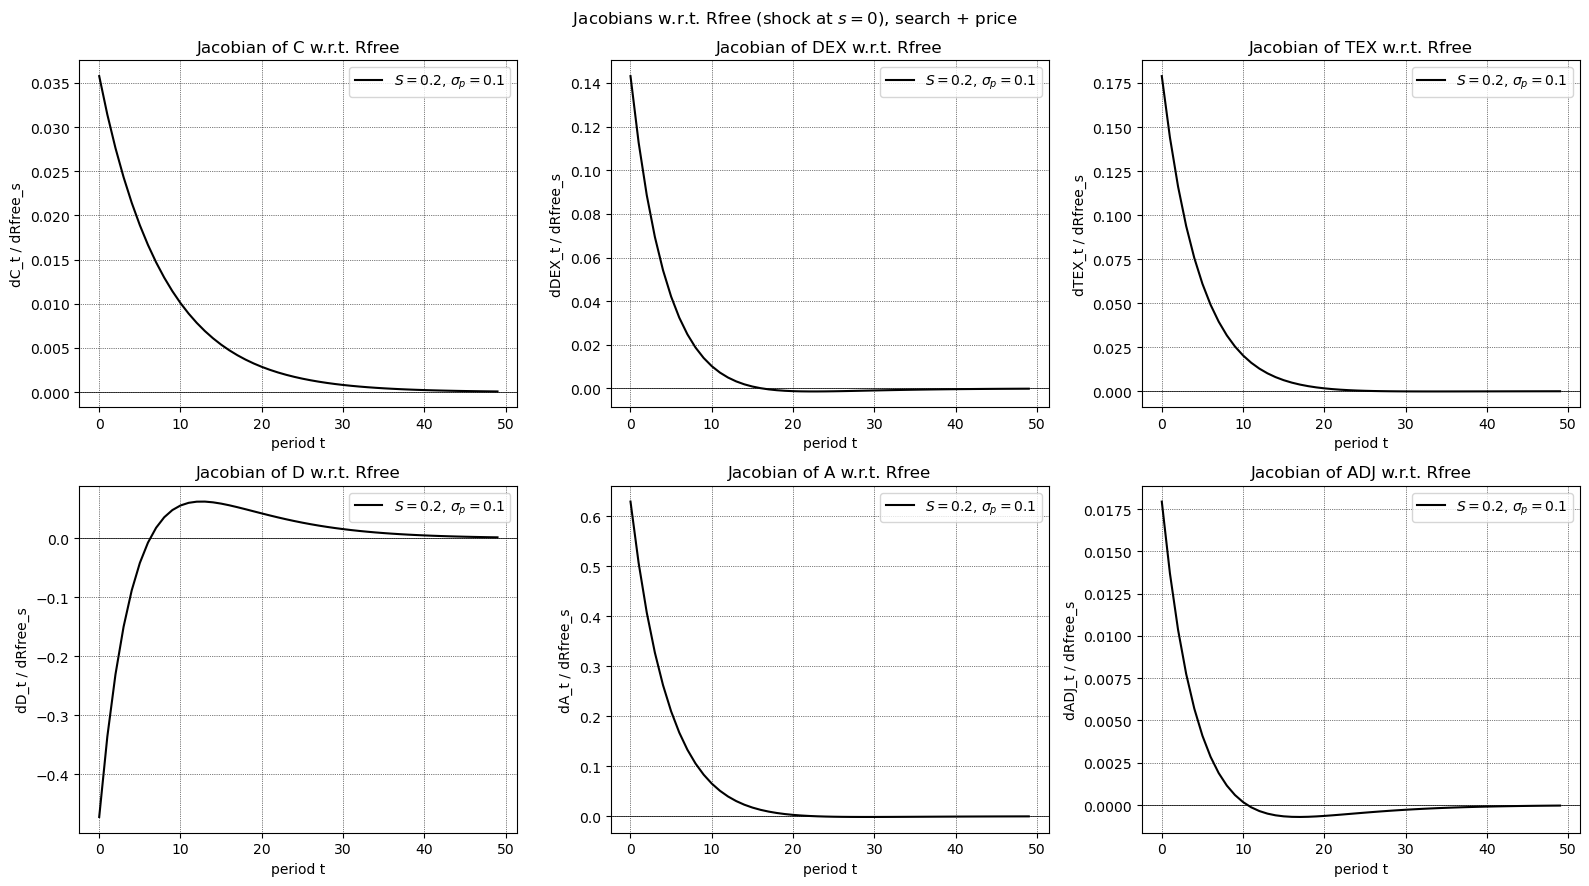

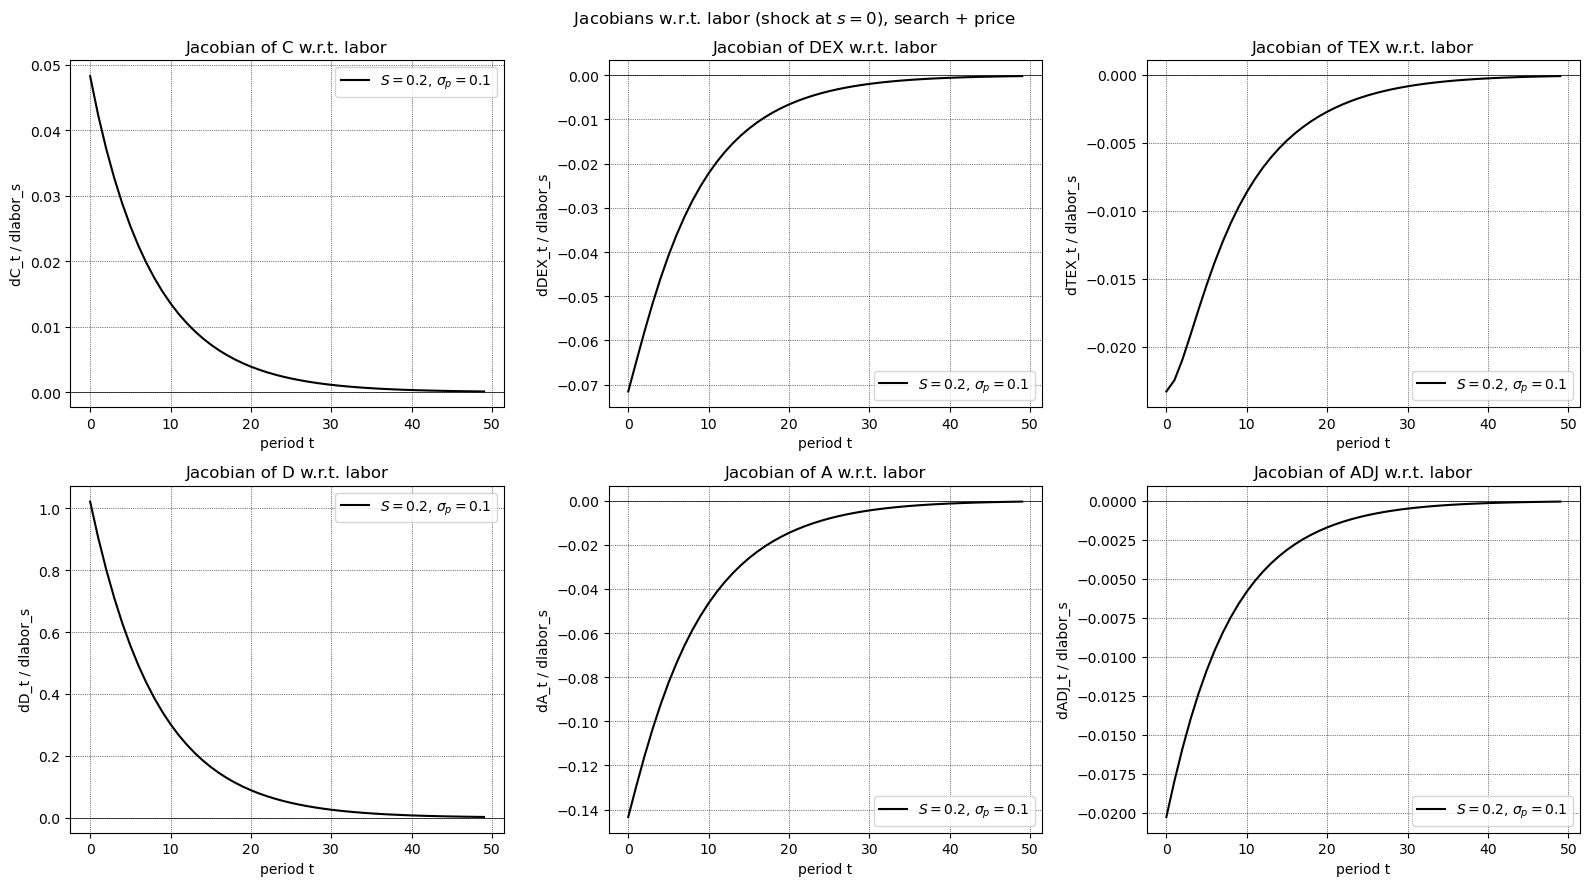

In [6]:
# Overlay Jacobians across parameter values (IRF to period-0 shock)
# Linestyles follow Figures_Durable.ipynb smoothing overlays.
shock_s = 0  # column of Jacobian = date of shock

# --- Rfree ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_Rfree"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. Rfree")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dRfree_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"Jacobians w.r.t. Rfree (shock at $s=0$), search + price")
fig.tight_layout()
plt.show()

# --- labor ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_labor"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. labor")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dlabor_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"Jacobians w.r.t. labor (shock at $s=0$), search + price")
fig.tight_layout()
plt.show()


In [7]:
# Save steady states and Jacobians as separate pickles
ss_payload = {
    "channel": results[0]["channel"],
    "param_name": results[0]["param_name"],
    "param_col": results[0]["param_col"],
    "param_values": [r["param"] for r in results],
    "labels": [r["label"] for r in results],
    "steady_states": {r["param"]: r["ss"] for r in results},
    "kink_euler": {r["param"]: r["kink_euler"] for r in results},
    "kink_euler_t": 0,
    "ss_table": ss_table,
}

jac_meta = dict(
    channel=results[0]["channel"],
    param_name=results[0]["param_name"],
    param_col=results[0]["param_col"],
    param_values=[r["param"] for r in results],
    labels=[r["label"] for r in results],
    T=T,
    shock_s_plotted=0,
)

jac_payload_Rfree = {
    **jac_meta,
    "shk_param": "Rfree",
    "jacobians": {r["param"]: r["jacobians_Rfree"] for r in results},
}
jac_payload_labor = {
    **jac_meta,
    "shk_param": "labor",
    "jacobians": {r["param"]: r["jacobians_labor"] for r in results},
}

ss_path = OUT_DIR / "DurableModel_Combined_Inf_SS.pkl"
jac_path_Rfree = OUT_DIR / "DurableModel_Combined_Inf_Jacobians_Rfree.pkl"
jac_path_labor = OUT_DIR / "DurableModel_Combined_Inf_Jacobians_labor.pkl"
with open(ss_path, "wb") as f:
    pickle.dump(ss_payload, f)
with open(jac_path_Rfree, "wb") as f:
    pickle.dump(jac_payload_Rfree, f)
with open(jac_path_labor, "wb") as f:
    pickle.dump(jac_payload_labor, f)

elapsed = time.time() - start_time
print(f"Saved {ss_path.resolve()}")
print(f"Saved {jac_path_Rfree.resolve()}")
print(f"Saved {jac_path_labor.resolve()}")
print("Done in", str(datetime.timedelta(seconds=elapsed)))


Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Combined_Inf_SS.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Combined_Inf_Jacobians_Rfree.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Combined_Inf_Jacobians_labor.pkl
Done in 0:04:26.977728


### Diagnostics


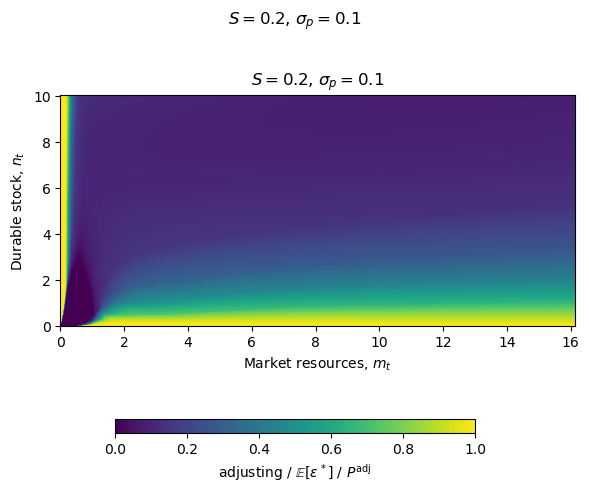

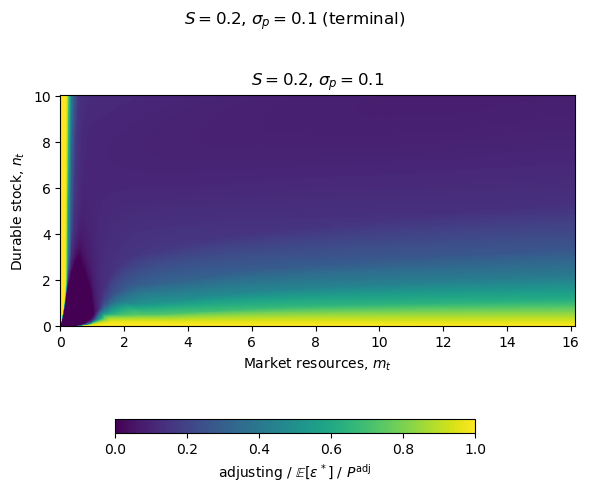

In [8]:
# 1. SS bands in solution [0]
title = param_labels[0]
plot_case_heatmaps([model], [title], 0, "Combined_Inf_Test", suptitle=title)


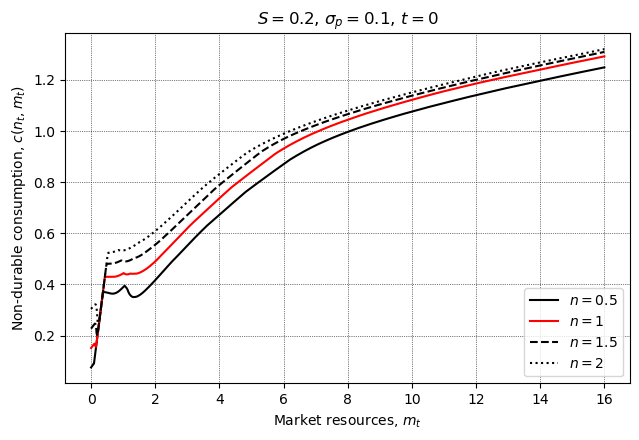

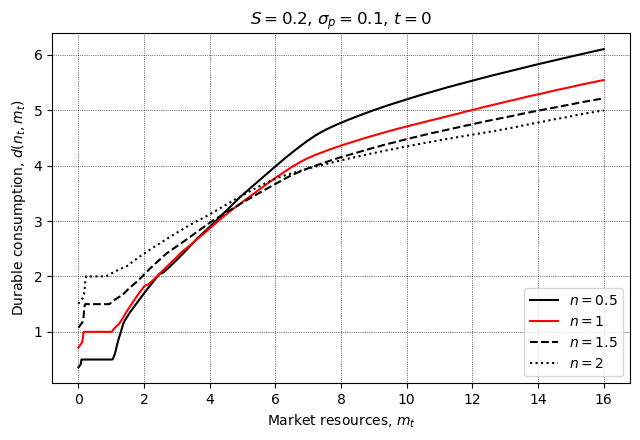

In [9]:
# 2. cFunc / dFunc for different n's
title = param_labels[0]
plot_combined_policies([model], [title], title, "Combined_Inf_Test", t=0)


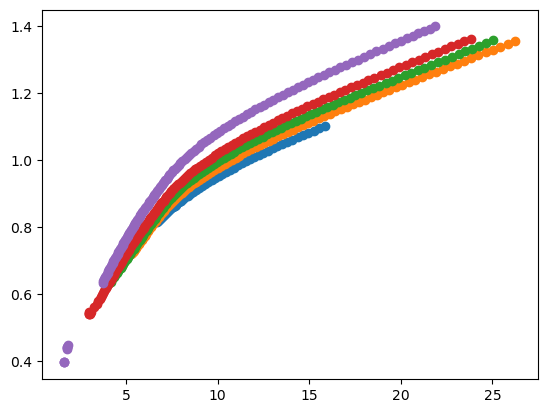

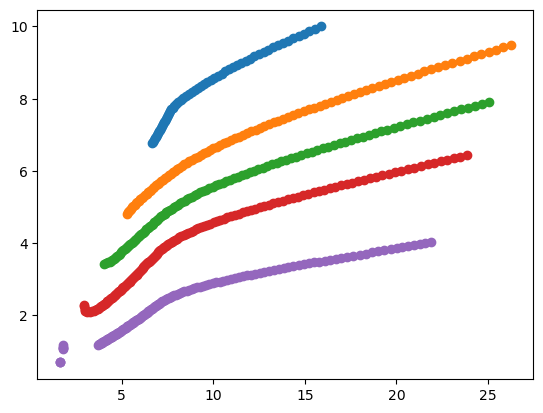

In [10]:
# 3. cFuncAdj scatter plot of post-FUES
plt.scatter(model.solution[0].xAdj_post_list[0], model.solution[0].cAdj_post_list[0])
plt.scatter(model.solution[0].xAdj_post_list[1], model.solution[0].cAdj_post_list[1])
plt.scatter(model.solution[0].xAdj_post_list[2], model.solution[0].cAdj_post_list[2])
plt.scatter(model.solution[0].xAdj_post_list[3], model.solution[0].cAdj_post_list[3])
plt.scatter(model.solution[0].xAdj_post_list[4], model.solution[0].cAdj_post_list[4])
plt.show()

plt.scatter(model.solution[0].xAdj_post_list[0], model.solution[0].dAdj_post_list[0])
plt.scatter(model.solution[0].xAdj_post_list[1], model.solution[0].dAdj_post_list[1])
plt.scatter(model.solution[0].xAdj_post_list[2], model.solution[0].dAdj_post_list[2])
plt.scatter(model.solution[0].xAdj_post_list[3], model.solution[0].dAdj_post_list[3])
plt.scatter(model.solution[0].xAdj_post_list[4], model.solution[0].dAdj_post_list[4])
plt.show()


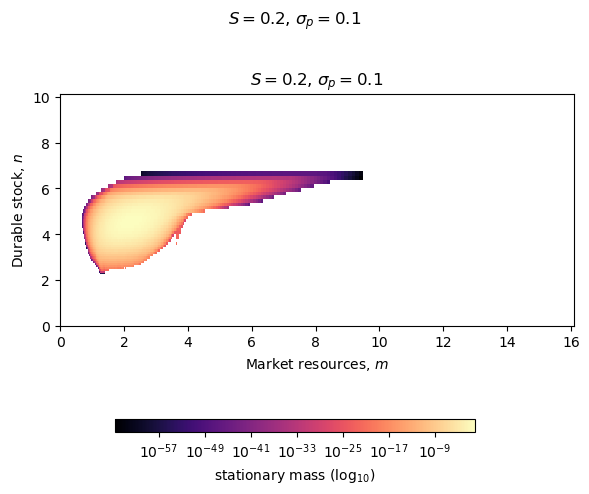

In [11]:
# 4. Ergodic distribution (after compute_steady_state)
title = param_labels[0]
plot_ergodic_heatmaps([model], [title], "Combined_Inf_Test_erg.pdf", suptitle=title)


$S = 0.2$, $\sigma_{p} = 0.1$: E_mu[P(adj)]=0.128983 (ADJ_ss=0.128983); P(adj) in [0, 1]; mass P<=0.001: 0.0000, continuous (0.001<P<0.999): 1.0000, P>=0.999: 0.0000; share of ADJ flow from continuous band: 1.000


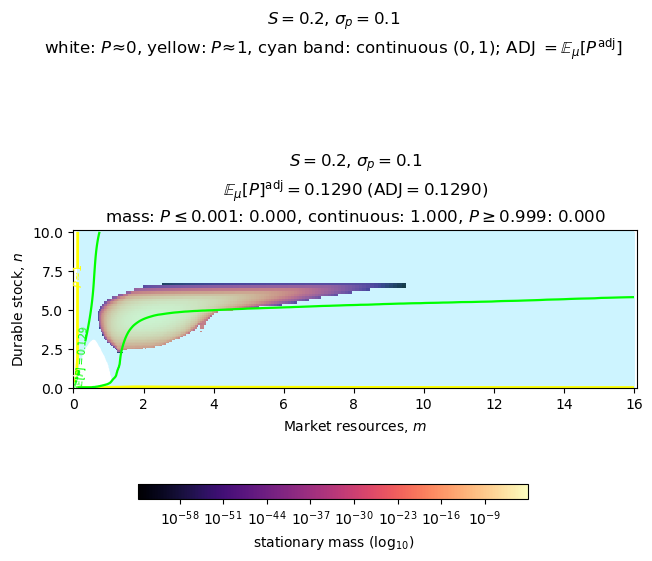

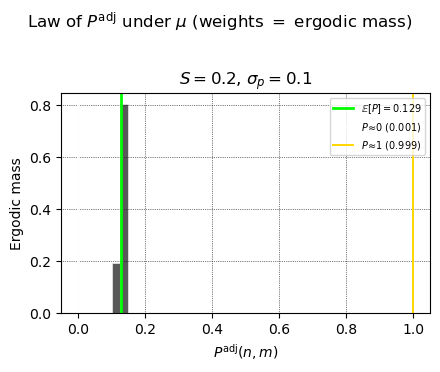

In [12]:
# 5. Ergodic mass overlaid with Ss adjusting contours (border mass)
# White / yellow lines: P≈0 and P≈1 frontiers; cyan shade: continuous (0,1) band
title = param_labels[0]
plot_ergodic_ss_overlay(
    [model], [title], "Combined_Inf_Test_erg_Ss.pdf",
    suptitle=title, border=(1e-3, 1.0 - 1e-3),
)


---
## Interpolant vs cond SS and Jacobians

The default `compute_steady_state` / `calc_jacobian` interpolate the solver's
mixed policies and `adjusting` onto the histogram grid.

`compute_steady_state_cond` / `calc_jacobian_cond` interpolate only keeper /
adjuster *conditionals*, rebuild continuation values, and re-combine on that
grid (search / EV taste / hard max).


In [13]:
# Snapshot interpolant SS / Jacobians, then recompute with the cond method.
ss_interp = dict(results[-1]["ss"])
jac_R_interp = results[-1]["jacobians_Rfree"]
jac_L_interp = results[-1]["jacobians_labor"]
title = param_labels[0]

print("Computing cond SS and Jacobians ...")
model.compute_steady_state_cond()
ss_cond = dict(
    C=float(model.C_ss),
    D=float(model.D_ss),
    DEX=float(model.DEX_ss),
    TEX=float(model.TEX_ss),
    A=float(model.A_ss),
    ADJ=float(model.ADJ_ss),
)
J_C, J_DEX, J_TEX, J_D, J_A, J_ADJ = model.calc_jacobian_cond("Rfree", T)
jac_R_cond = dict(C=J_C, DEX=J_DEX, TEX=J_TEX, D=J_D, A=J_A, ADJ=J_ADJ)
J_C, J_DEX, J_TEX, J_D, J_A, J_ADJ = model.calc_jacobian_cond("labor", T)
jac_L_cond = dict(C=J_C, DEX=J_DEX, TEX=J_TEX, D=J_D, A=J_A, ADJ=J_ADJ)
print("Cond SS / Jacobians done.")

ss_cmp = pd.DataFrame(
    {
        "interp": [ss_interp[k] for k in SS_KEYS],
        "cond": [ss_cond[k] for k in SS_KEYS],
    },
    index=SS_KEYS,
)
ss_cmp["diff"] = ss_cmp["cond"] - ss_cmp["interp"]
ss_cmp["pct"] = 100.0 * ss_cmp["diff"] / ss_cmp["interp"].replace(0.0, np.nan)
print(f"Steady-state: interpolant vs cond  ({title})")
display(ss_cmp.style.format("{:.6f}"))


Computing cond SS and Jacobians ...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\scipy\sparse\_index.py:151: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1172: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1165: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


Cond SS / Jacobians done.
Steady-state: interpolant vs cond  ($S = 0.2$, $\sigma_{p} = 0.1$)


,interp,cond,diff,pct
C,0.825727,0.825724,-0.000003,-0.000304
D,4.754836,4.754920,0.000085,0.001780
DEX,0.237742,0.237746,0.000004,0.001780
TEX,1.063469,1.063470,0.000002,0.000162
A,1.197889,1.197807,-0.000082,-0.006869
ADJ,0.128983,0.128993,0.000010,0.007885


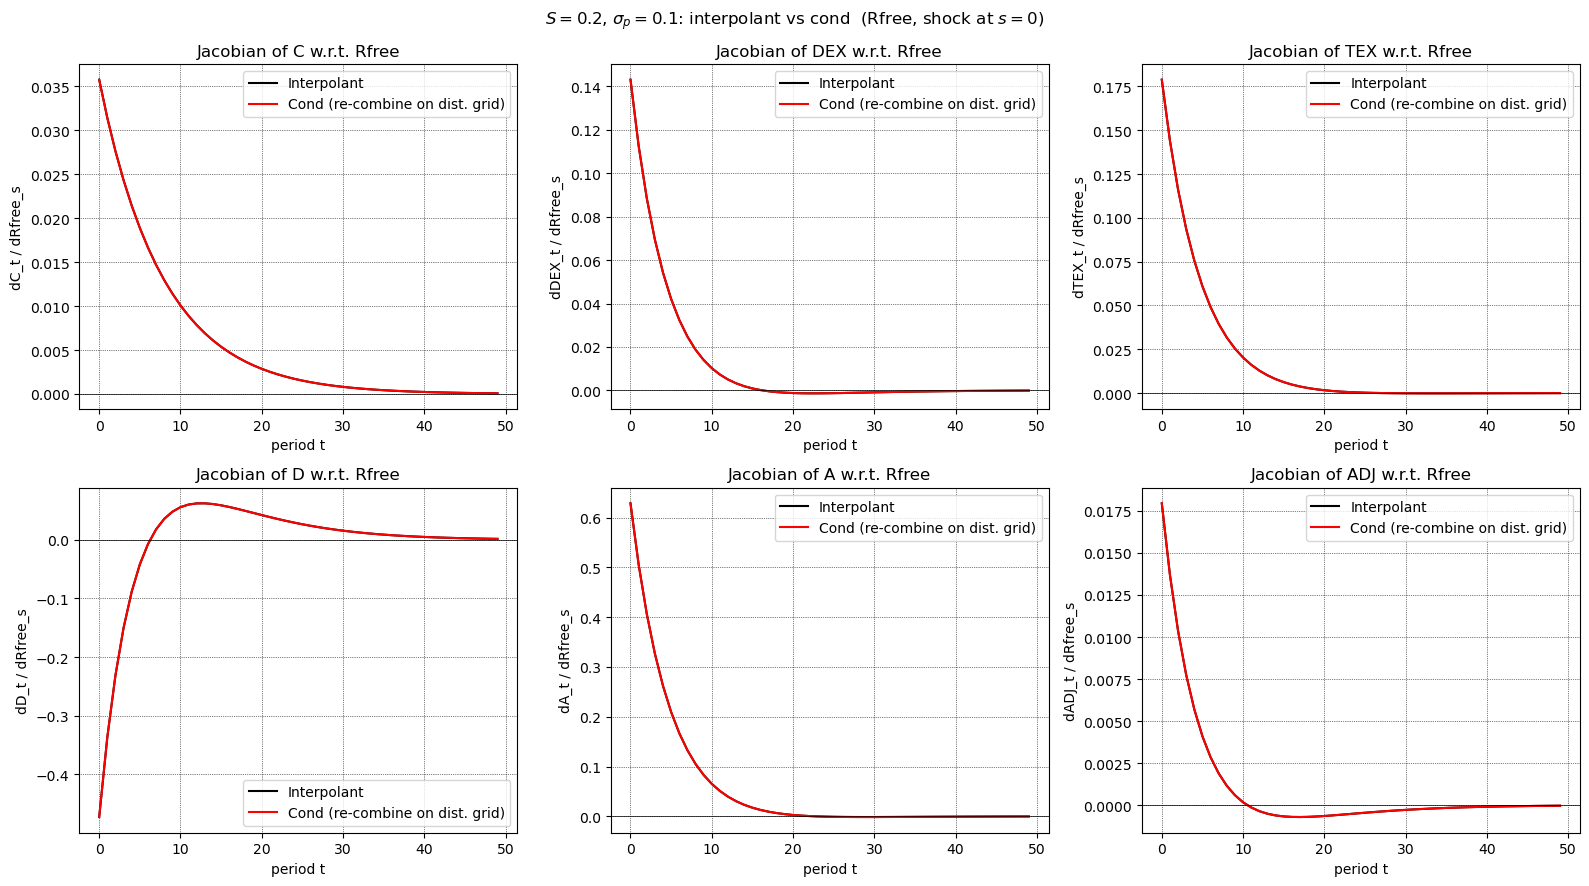

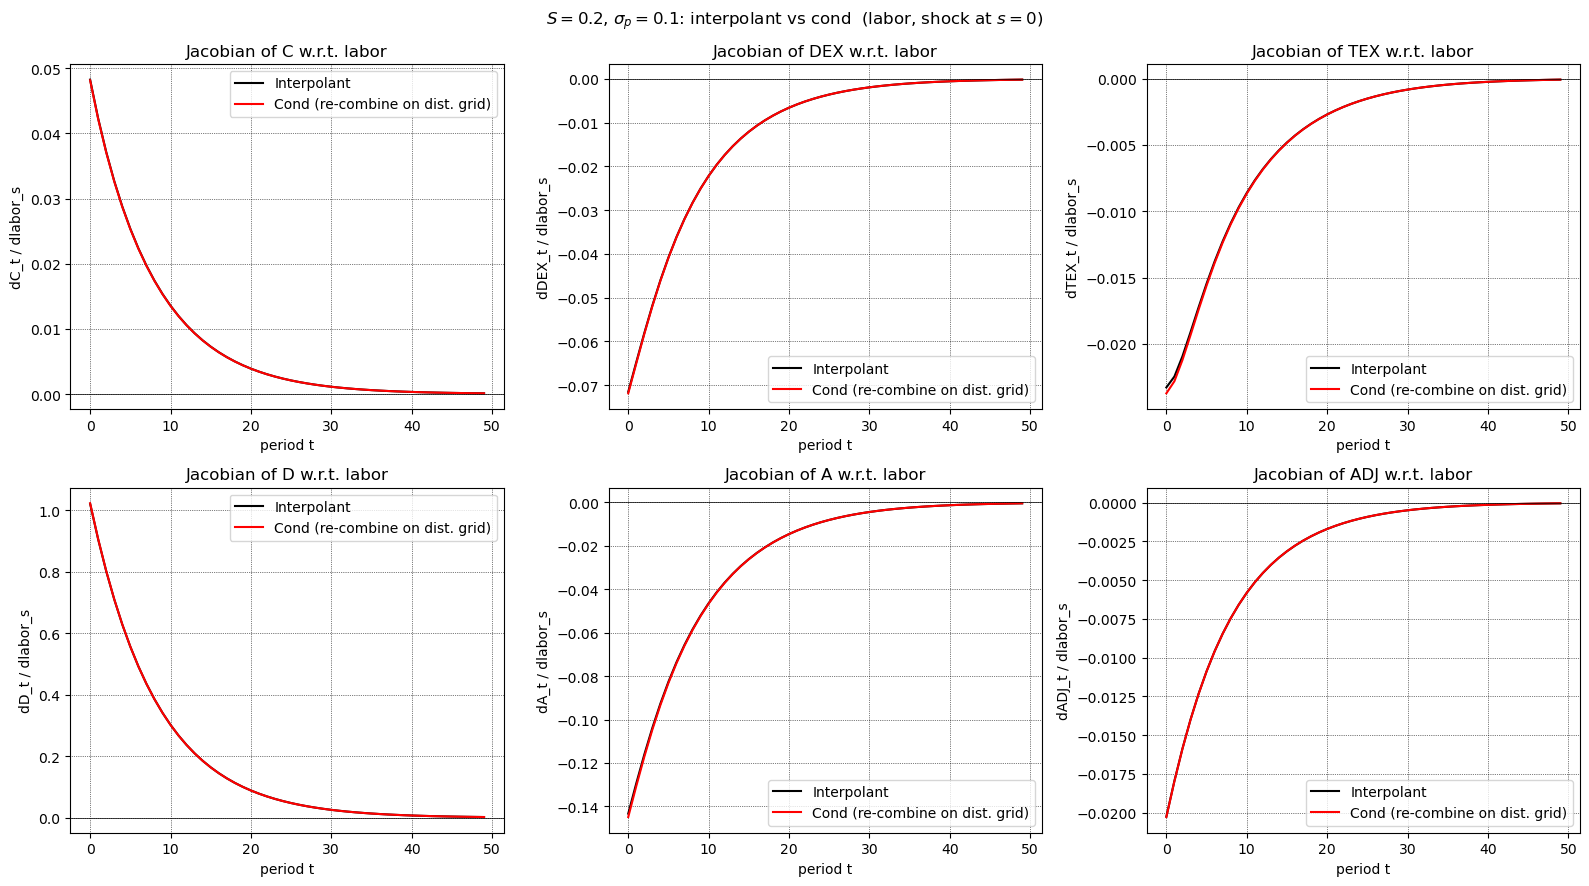

In [14]:
# Overlay interpolant vs cond Jacobians (IRF to period-0 shock)
shock_s = 0

def _plot_jac_compare(jac_interp, jac_cond, shk_name):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    versions = [
        (jac_interp, "Interpolant", LINE_STYLES[0]),
        (jac_cond, "Cond (re-combine on dist. grid)", LINE_STYLES[1]),
    ]
    for ax, name in zip(axes.flat, JAC_KEYS):
        for Jdict, lab, (color, ls) in versions:
            ax.plot(Jdict[name][:, shock_s], color=color, linestyle=ls, label=lab)
        ax.axhline(0.0, color="k", lw=0.5)
        ax.set_title(f"Jacobian of {name} w.r.t. {shk_name}")
        ax.set_xlabel("period t")
        ax.set_ylabel(f"d{name}_t / d{shk_name}_s")
        ax.grid(color="k", linestyle=":", linewidth=0.5)
        ax.legend(loc="best")
    fig.suptitle(rf"{title}: interpolant vs cond  ({shk_name}, shock at $s=0$)")
    fig.tight_layout()
    plt.show()

_plot_jac_compare(jac_R_interp, jac_R_cond, "Rfree")
_plot_jac_compare(jac_L_interp, jac_L_cond, "labor")
